# Analysis of the dataset

## 0. Imports & Config

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipaddress


DATASET_PATH = r"C:\Users\User\Documents\Key Future Docs\Projects\Phising URL\dataset\new_data_urls.csv"

## 1. Load the dataset

In [2]:
df = pd.read_csv(DATASET_PATH)

df.reset_index(drop=True, inplace=True)
df.rename(columns={"status": "is_phishing"}, inplace=True)
df['is_phishing'] = df['is_phishing'] == 1

print("Total number of URLs in the dataset: ", len(df))
df.sample(10, ignore_index=True).sort_values(by="is_phishing")

Total number of URLs in the dataset:  822010


,url,is_phishing
0,joslinsalesltd.com/kro1gx,False
2,http://certs-account-recovery-support-amazon.i...,False
3,smpn2karangawen.sch.id/wp-admin/js/Welcomeback...,False
6,allegro.pl-nowy-regulamin2157.ubdfvn.eu,False
1,fafarazzi.com/gossip/838892/Nick-Stahl--Rose-M...,True
4,meniketti.com/phil.html,True
5,corporationwiki.com/Florida/Sanibel/redpath-pe...,True
7,efilmcritic.com/review.php?movie=14297&reviewe...,True
8,ebooksread.com/authors-eng/england-society-for...,True
9,fanbase.com/1-Jean-Guy-Gendron,True


In [3]:
print(f"The shape of the dataset is: {df.shape} with data types: {df.dtypes}")
print(f"Number of phishing URLs: {df['is_phishing'].where(df['is_phishing'] == True).count()}")
print(f"Number of legitimate URLs: {df['is_phishing'].where(df['is_phishing'] == False).count()}")
print(f"Number of URLs with NaN values: {df['url'].isnull().sum()}")
print(f"Number of labels with NaN values: {df['is_phishing'].isnull().sum()}")

The shape of the dataset is: (822010, 2) with data types: url            object
is_phishing      bool
dtype: object
Number of phishing URLs: 427028
Number of legitimate URLs: 394982
Number of URLs with NaN values: 0
Number of labels with NaN values: 0


## 2. Split URLs into protocols, domains and paths

In [4]:
def is_ip(url):
    try:
        ipaddress.ip_address(url)
        return True
    except:
        return False

split_urls = df['url'].str.replace('//','/').str.split('/')
result = []
for url in split_urls:
    url_parts = []
    domain = []
    if url[0] == 'http:' or url[0] == 'https:':
        url_parts.append(url[0].replace(':', '')) # protocol
        url_parts.append(url[1]) # subdomain & domain
        url_parts.append(url[2:]) # path
        domain = url[1].split('.')
    elif len(url) >= 2:
        url_parts.append(None) # protocol
        url_parts.append(url[0]) # subdomain & domain
        url_parts.append(url[1:]) # path
        domain = url[0].split('.')
    else:
        url_parts.append(None) # protocol
        url_parts.append(url[0]) # subdomain & domain
        url_parts.append(None) # path
        domain = url[0].split('.')

    if len(domain) > 1:
        url_parts.append(domain[1:-1]) # subdomains
        url_parts.append(domain[-1]) # tld

    if is_ip(url):
        url_parts.append(True)
    else:
        url_parts.append(False)

    result.append(url_parts)

df = pd.concat([df, pd.DataFrame(result, columns=['protocol', 'domain', 'path', 'subdomains', 'tld', 'is_ip'])], axis=1)
df.sample(10, ignore_index=True).sort_values(by="is_phishing")

,url,is_phishing,protocol,domain,path,subdomains,tld,is_ip
0,https://moncompteenligneactivation.fr/labanque...,False,https,moncompteenligneactivation.fr,"[labanquepostale, 273c1]",[],fr,False
2,https://bfdb.63279.cn/,False,https,bfdb.63279.cn,[],[63279],cn,False
3,b2b.palbeck.de/skin/Gdoccc/,False,None,b2b.palbeck.de,"[skin, Gdoccc, ]",[palbeck],de,False
4,https://1205.check.cy-email.com,False,https,1205.check.cy-email.com,[],"[check, cy-email]",com,False
6,tempotac.biz/test/login.php,False,None,tempotac.biz,"[test, login.php]",[],biz,False
7,important-information-set-client-pipoypal.000w...,False,None,important-information-set-client-pipoypal.000w...,None,[000webhostapp],com,False
1,innercityadvisors.org/2010/04/portfolio-compan...,True,None,innercityadvisors.org,"[2010, 04, portfolio-companies-in-the-news, ]",[],org,False
5,target.com/p/American-Music-The-Hightone-Recor...,True,None,target.com,"[p, American-Music-The-Hightone-Records-Story-...",[],com,False
8,en.wikipedia.org/wiki/Canal_Indigo,True,None,en.wikipedia.org,"[wiki, Canal_Indigo]",[wikipedia],org,False
9,spoke.com/info/p2yplR2/MichelLacombe,True,None,spoke.com,"[info, p2yplR2, MichelLacombe]",[],com,False


# 3. Search for patterns in the dataset

In [ ]:
def create_bar_plot(df_temp, column, title, limit_x=None, limit_y=None):
    phishing_counts = df_temp.where(df_temp['is_phishing'] == True).groupby(column)['is_phishing'].count()
    legitimate_counts = df_temp.where(df_temp['is_phishing'] == False).groupby(column)['is_phishing'].count()

    ratio = legitimate_counts / phishing_counts + legitimate_counts

    ax = ratio.plot(kind='bar', figsize=(10, 5))
    if limit_x is not None:
        ax.set_xlim(0, limit_x)
    if limit_y is not None:
        ax.set_ylim(0, limit_y)
    ax.axhline(1, color='gray', linestyle='--', linewidth=1)
    plt.title(title)
    plt.xlabel(column)
    plt.ylabel('Legitimate / phishing ratio')
    plt.show()

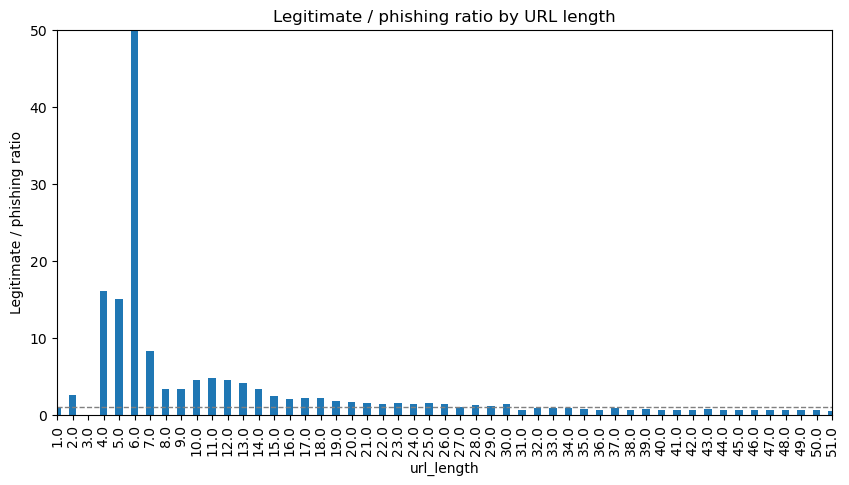

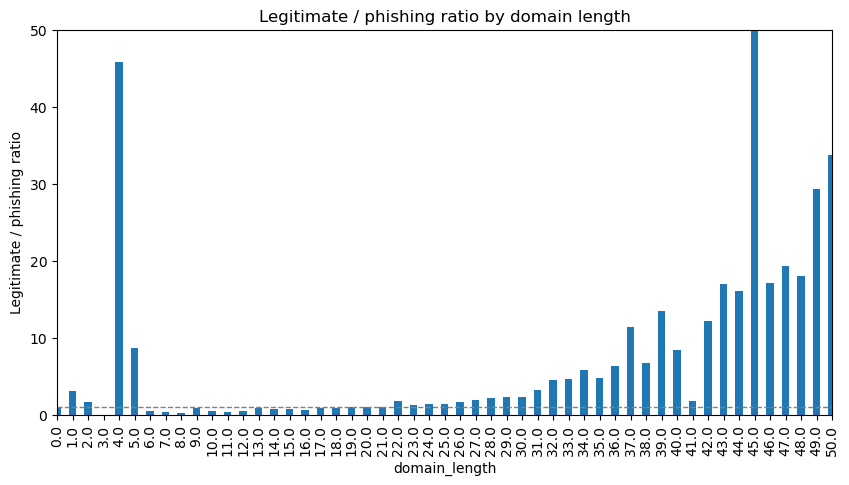

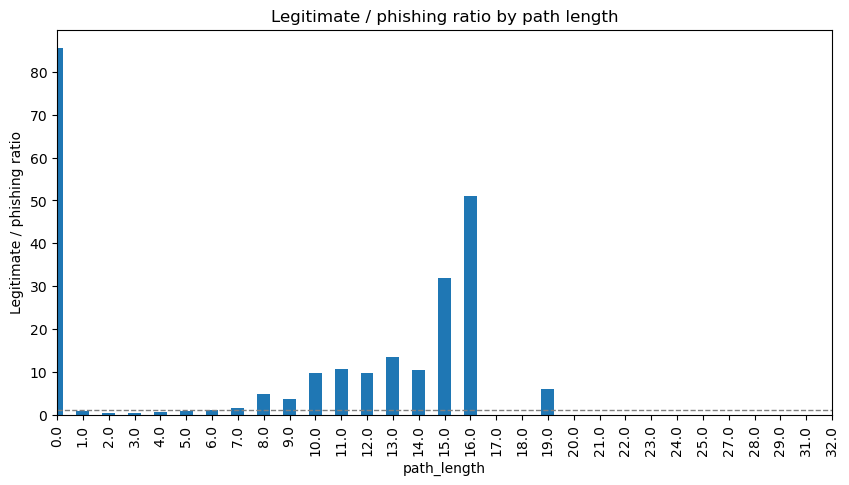

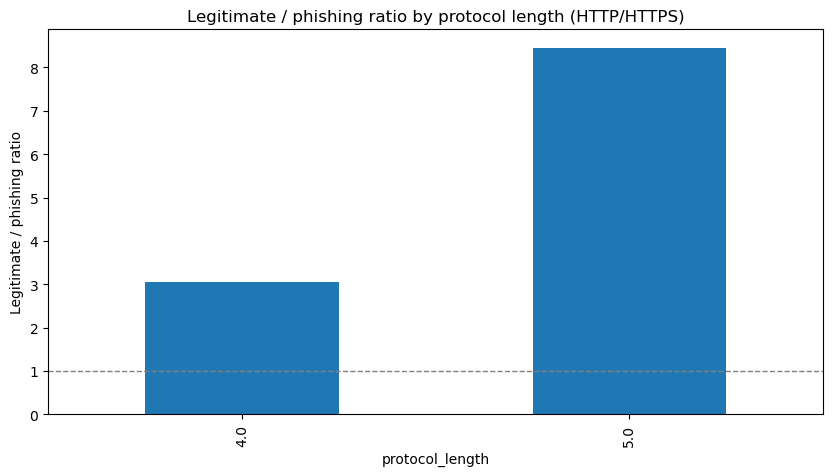

In [6]:
length_plots = df.copy()
length_plots['url_length'] = length_plots['url'].str.len()
create_bar_plot(length_plots, 'url_length', 'Legitimate / phishing ratio by URL length', 50, 50)

length_plots['domain_length'] = length_plots['domain'].str.len()
create_bar_plot(length_plots, 'domain_length', 'Legitimate / phishing ratio by domain length', 50, 50)

length_plots['path_length'] = length_plots['path'].str.len()
create_bar_plot(length_plots, 'path_length', 'Legitimate / phishing ratio by path length', 30)

length_plots['protocol_length'] = length_plots['protocol'].str.len()
create_bar_plot(length_plots, 'protocol_length', 'Legitimate / phishing ratio by protocol length (HTTP/HTTPS)')

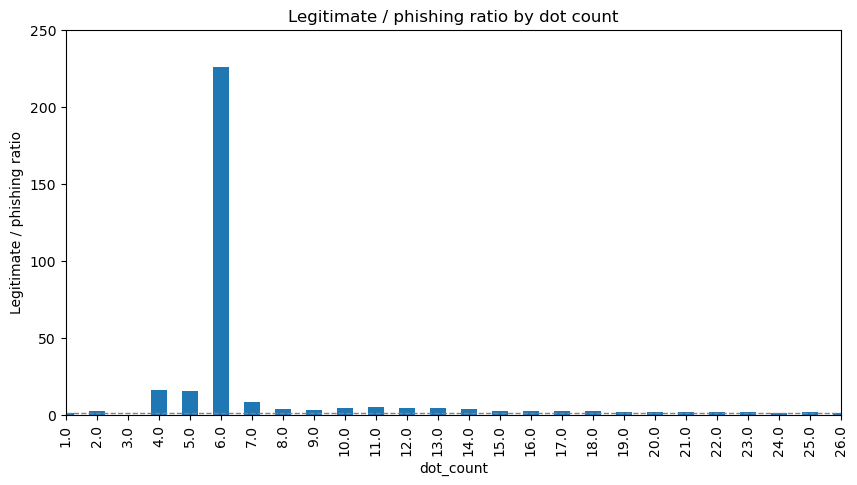

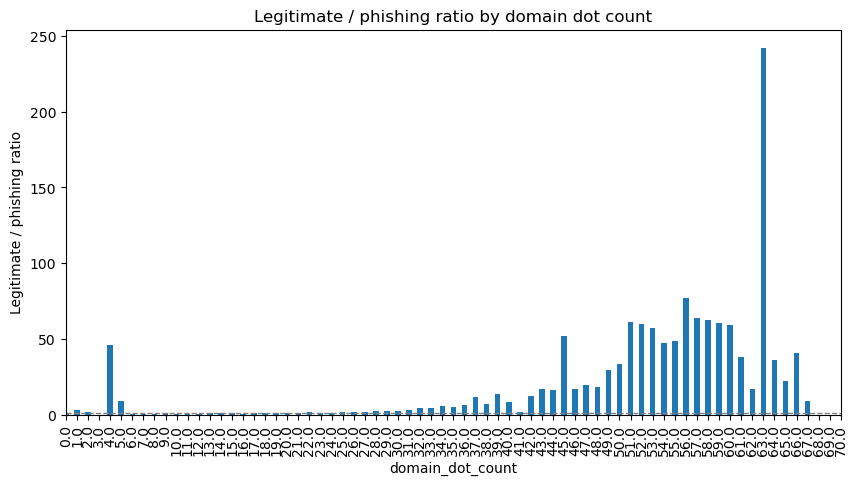

In [7]:
dot_plots = df.copy()
dot_plots['dot_count'] = dot_plots['url'].str.count('.')
create_bar_plot(dot_plots, 'dot_count', 'Legitimate / phishing ratio by dot count', 25, 250)

# per section dot count
dot_plots['domain_dot_count'] = dot_plots['domain'].str.count('.')
create_bar_plot(dot_plots, 'domain_dot_count', 'Legitimate / phishing ratio by domain dot count', 70)

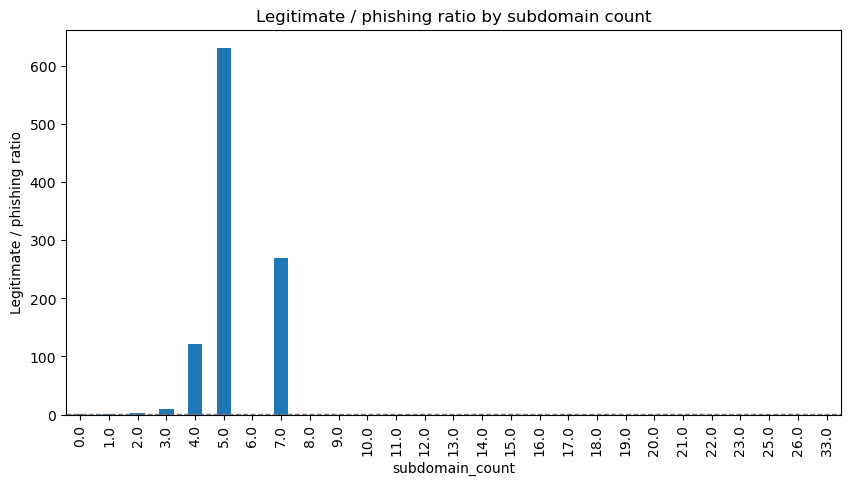

In [8]:
subdomain_plot = df.copy()
subdomain_plot['subdomain_count'] = subdomain_plot['subdomains'].str.len()
create_bar_plot(subdomain_plot, 'subdomain_count', 'Legitimate / phishing ratio by subdomain count')

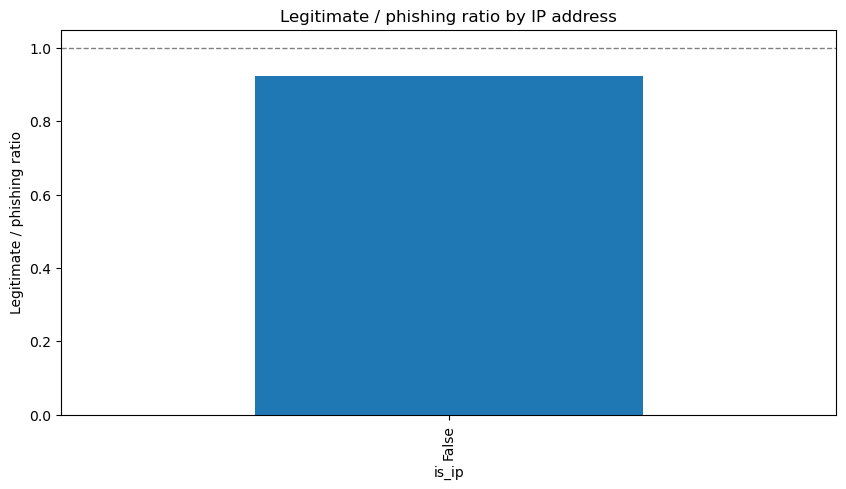

In [9]:
ip_plot = df.copy()
create_bar_plot(ip_plot, 'is_ip', 'Legitimate / phishing ratio by IP address')

In [10]:
top_level_domain_plot = df.copy()
create_bar_plot(top_level_domain_plot, 'tld', 'Legitimate / phishing ratio by top level domain')

c:\Users\User\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\User\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 140 (\x8c) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\User\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 153 (\x99) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\User\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 159 (\x9f) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\User\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\User\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129 (\x81) m

ValueError: 
tñø­½½qx½NºPmx$Aì&ÝIhÂéc¶A9®cì3ßyiÚý~JÍf]$ö M¸°;xÃu0IÅ@xõe^cÃ ¸´ÞO7B~FrØ\<kÅb{T!Ìé       r?kX-YÇS@T)LeaÃ}°¡ùï4ºkïá2¢kEì¬ôfsçË×ÛQìê{o£UÜ§D©l½±±äâqôó¼-â0èÙ¦kvîdàQÎé6°Ò¼©
                 ^
ParseException: Expected end of text, found '$'  (at char 17), (line:1, col:18)

<Figure size 1000x500 with 1 Axes>